## CNN Mini Project
### Mini Project: COVID-19 Detection from Chest X-rays using CNN
### Name: Samruddhi Mulmule

### Objective

A healthcare startup aims to accelerate and improve COVID-19 diagnosis using deep learning technologies. The current testing procedures are time-consuming and rely heavily on manual radiological examination, which limits scalability in pandemic situations.

As a data scientist, your task is to build a Convolutional Neural Network (CNN) model that can automatically detect COVID-19 from chest X-ray images. This solution can help hospitals:

· Reduce diagnosis time.

· Minimize burden on radiologists.

· Scale testing across regions with limited radiological expertise.

This project allows you to apply deep learning concepts, understand how CNNs process image data, and build real-world applications that can assist the medical community.

### Dataset

Dataset Link: https://www.kaggle.com/datasets/pranavraikokte/covid19-image-dataset

The dataset contains:

· COVID-19 chest X-ray images

· Normal (no disease) chest X-ray images

· Viral Pneumonia chest X-ray images

---

### Data Dictionary

Each image is labelled into one of the following classes:

· COVID-19 – Confirmed COVID infection.

· Viral Pneumonia – Non-COVID lung infection.

· Normal – No visible lung abnormality.

### Solution

#### Downloading Dataset

In [1]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/

In [2]:
!kaggle datasets download -d pranavraikokte/covid19-image-dataset

Dataset URL: https://www.kaggle.com/datasets/pranavraikokte/covid19-image-dataset
License(s): CC-BY-SA-4.0
100% 158M/158M [00:13<00:00, 12.5MB/s]



In [3]:
import zipfile
zip_ref = zipfile.ZipFile('/content/covid19-image-dataset.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [4]:
train_path = "/content/Covid19-dataset/train"

test_path = "/content/Covid19-dataset/test"

#### Importing Libraries

In [5]:
import os
import numpy as np
import pandas as pd
from PIL import Image

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import *
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications import VGG16, ResNet50

from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, accuracy_score, f1_score)
from sklearn.utils.class_weight import compute_class_weight

#### Data Preprocessing

In [6]:
IMG_SIZE = 224
BATCH = 32

# 80% train / 20% validation from the train folder
gen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_data = gen.flow_from_directory(
    train_path, target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH,
    class_mode='categorical', subset='training', shuffle=True)

val_data = gen.flow_from_directory(
    train_path, target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH,
    class_mode='categorical', subset='validation', shuffle=False)

# Test data from the test folder
test_gen = ImageDataGenerator(rescale=1./255)
test_data = test_gen.flow_from_directory(
    test_path, target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH,
    class_mode='categorical', shuffle=False)

class_names = list(train_data.class_indices.keys())
print('Classes:', train_data.class_indices)
print('Train:', train_data.samples, ' Validation:', val_data.samples, ' Test:', test_data.samples)

Found 201 images belonging to 3 classes.
Found 50 images belonging to 3 classes.
Found 66 images belonging to 3 classes.
Classes: {'Covid': 0, 'Normal': 1, 'Viral Pneumonia': 2}
Train: 201  Validation: 50  Test: 66


#### EDA

Class Distribution

Train folder: {'Covid': 111, 'Normal': 70, 'Viral Pneumonia': 70}
Test folder : {'Covid': 26, 'Normal': 20, 'Viral Pneumonia': 20}


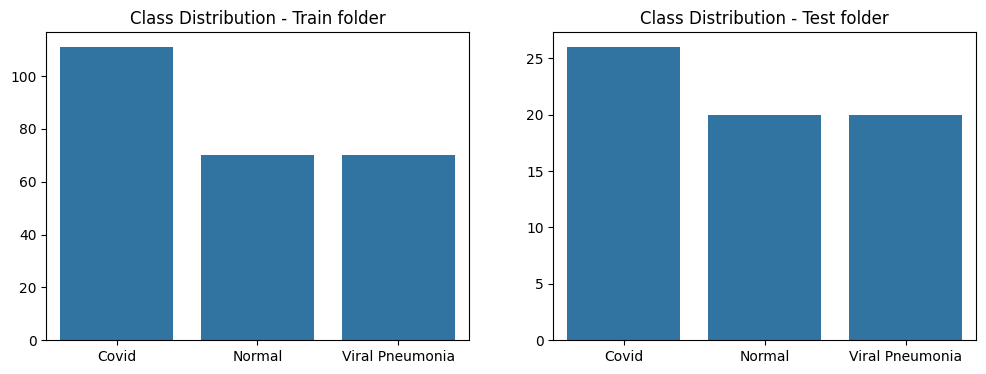

In [7]:
# Dataset size per class (train and test folders)
train_counts = {c: len(os.listdir(os.path.join(train_path, c))) for c in sorted(os.listdir(train_path))}
test_counts = {c: len(os.listdir(os.path.join(test_path, c))) for c in sorted(os.listdir(test_path))}

print('Train folder:', train_counts)
print('Test folder :', test_counts)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.barplot(x=list(train_counts.keys()), y=list(train_counts.values()))
plt.title('Class Distribution - Train folder')
plt.subplot(1, 2, 2)
sns.barplot(x=list(test_counts.keys()), y=list(test_counts.values()))
plt.title('Class Distribution - Test folder')
plt.show()

Displaying Sample Images

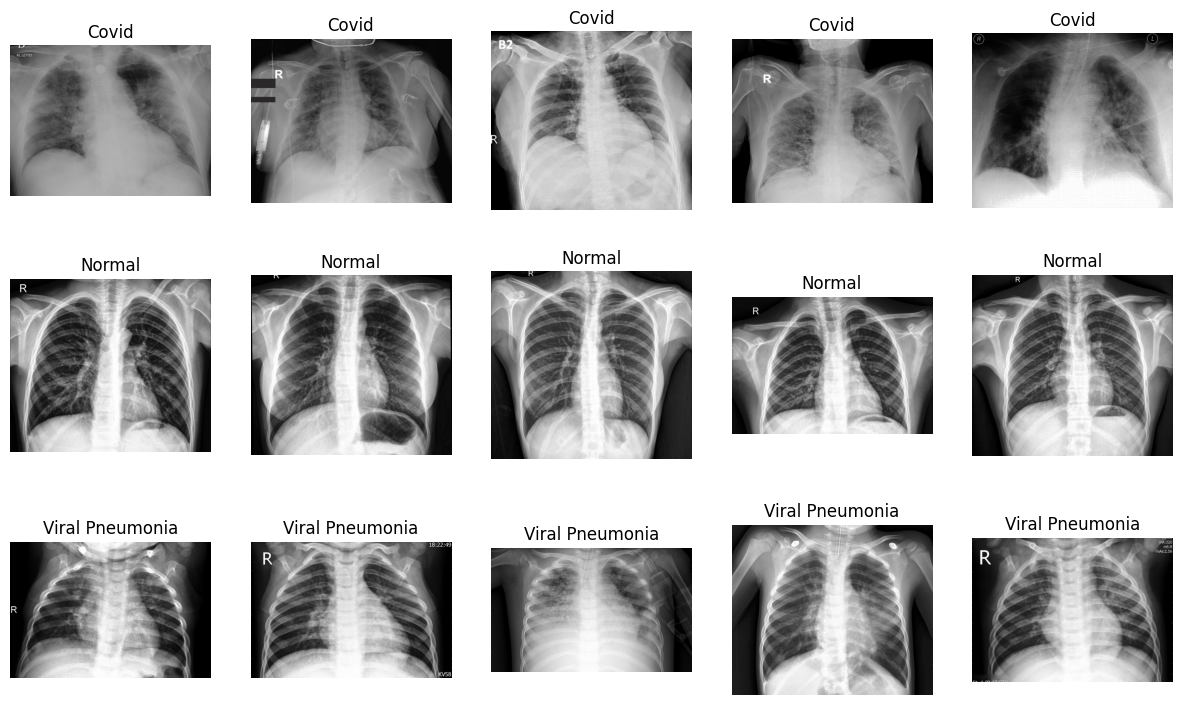

In [8]:
plt.figure(figsize=(15, 9))
i = 1
for cls in sorted(os.listdir(train_path)):
    folder = os.path.join(train_path, cls)
    for f in os.listdir(folder)[:5]:
        img = Image.open(os.path.join(folder, f)).convert('RGB')
        plt.subplot(3, 5, i)
        plt.imshow(img)
        plt.title(cls)
        plt.axis('off')
        i += 1
plt.show()

#### Observations
- The classes are not equal in size - Covid has the most images, so there is mild class imbalance.
- X-rays of Normal lungs look clearer; Covid and Viral Pneumonia show hazy / cloudy patches, which is what the CNN has to learn.
- The dataset is small, so overfitting is a risk and augmentation will help.

### Handling Class Imbalance

In [9]:
classes = train_data.classes

weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(classes),
    y=classes
)

class_weights = dict(
    enumerate(weights)
)

print(class_weights)

{0: np.float64(0.7528089887640449), 1: np.float64(1.1964285714285714), 2: np.float64(1.1964285714285714)}


### Evaluation Function for all models

In [10]:
results = []        # rows for the comparison table
all_models = {}     # trained models, so we can save the best one

def plot_history(history, name):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train')
    plt.plot(history.history['val_accuracy'], label='Validation')
    plt.title(name + ' - Accuracy')
    plt.xlabel('Epoch')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train')
    plt.plot(history.history['val_loss'], label='Validation')
    plt.title(name + ' - Loss')
    plt.xlabel('Epoch')
    plt.legend()
    plt.show()

def evaluate(model, history, name):
    plot_history(history, name)

    probs = model.predict(test_data, verbose=0)
    y_pred = np.argmax(probs, axis=1)
    y_true = test_data.classes

    train_acc = model.evaluate(train_data, verbose=0)[1]
    test_acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='weighted')

    # ROC-AUC (one-vs-rest)
    y_true_onehot = to_categorical(y_true, num_classes=3)
    auc = roc_auc_score(y_true_onehot, probs)
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))

    print('Train accuracy   :', round(train_acc, 3))
    print('Test accuracy    :', round(test_acc, 3))
    print('F1 (weighted)    :', round(f1, 3))
    print('ROC-AUC (overall):', round(auc, 3))
    for i, c in enumerate(class_names):
        print('   ROC-AUC', c, ':', round(roc_auc_score(y_true_onehot[:, i], probs[:, i]), 3))
    print('Trainable params :', trainable)

    print('\nClassification report:')
    print(classification_report(y_true, y_pred, target_names=class_names))

    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(name + ' - Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    # Overfitting = train accuracy is more than 10 points above test accuracy
    overfit = 'Y' if (train_acc - test_acc) > 0.10 else 'N'
    results.append({'Model': name, 'Train Acc': round(train_acc, 3),
                    'Test Acc': round(test_acc, 3), 'F1 Score': round(f1, 3),
                    'ROC AUC': round(auc, 3), 'Trainable Params': trainable,
                    'Overfitting (Y/N)': overfit})
    all_models[name] = model

#### Model 1 : Basic CNN

In [11]:
cnn1 = Sequential([
    Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(3, activation='softmax')
])

cnn1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history1 = cnn1.fit(train_data, validation_data=val_data,
                    epochs=10, class_weight=class_weights)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.4378 - loss: 16.0840 - val_accuracy: 0.3200 - val_loss: 11.7714
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 789ms/step - accuracy: 0.6219 - loss: 2.6003 - val_accuracy: 0.4800 - val_loss: 2.9479
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 971ms/step - accuracy: 0.7114 - loss: 0.9281 - val_accuracy: 0.6400 - val_loss: 1.1058
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 949ms/step - accuracy: 0.8458 - loss: 0.2927 - val_accuracy: 0.8800 - val_loss: 0.5811
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 821ms/step - accuracy: 0.9701 - loss: 0.1119 - val_accuracy: 0.8600 - val_loss: 0.4641
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 803ms/step - accuracy: 0.9751 - loss: 0.0537 - val_accuracy: 0.9200 - val_loss: 0.4553
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 712ms/step - accuracy: 0.9950 - loss: 0.0191 - val_accuracy: 0.9200 - val_loss: 0.4282
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 876ms/step - accuracy: 1.0000 - loss: 0.0108 - val_accuracy: 0.9200 - val_loss:

In [12]:
loss1 , acc1 = cnn1.evaluate(test_data)

print(acc1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 696ms/step - accuracy: 0.8939 - loss: 0.3701
0.8939393758773804


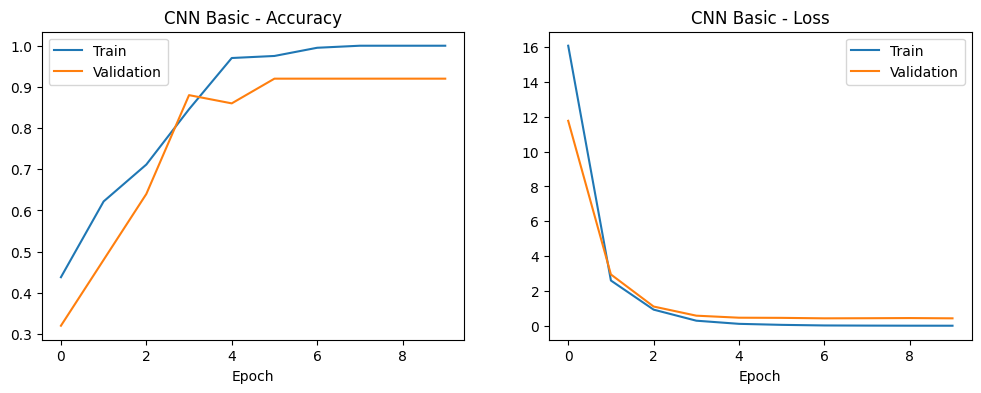

Train accuracy   : 1.0
Test accuracy    : 0.894
F1 (weighted)    : 0.889
ROC-AUC (overall): 0.977
   ROC-AUC Covid : 0.997
   ROC-AUC Normal : 0.992
   ROC-AUC Viral Pneumonia : 0.94
Trainable params : 50468227

Classification report:
                 precision    recall  f1-score   support

          Covid       0.90      1.00      0.95        26
         Normal       0.86      0.95      0.90        20
Viral Pneumonia       0.93      0.70      0.80        20

       accuracy                           0.89        66
      macro avg       0.90      0.88      0.88        66
   weighted avg       0.90      0.89      0.89        66



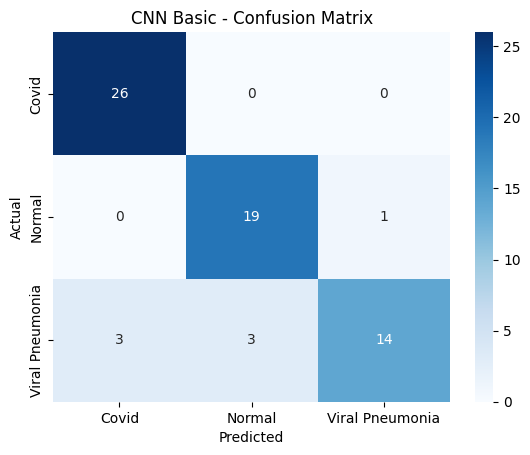

In [13]:
evaluate(cnn1, history1, 'CNN Basic')

There is a huge gap between training and testing accuracy which suggests the overfitting issue most likely because of class imbalance.

#### Model 2: CNN + Dropout

In [14]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

cnn2 = Sequential()

cnn2.add(Conv2D(32,(3,3),activation='relu',
                input_shape=(224,224,3)))
cnn2.add(MaxPooling2D())

cnn2.add(Conv2D(64,(3,3),activation='relu'))
cnn2.add(MaxPooling2D())

cnn2.add(Conv2D(128,(3,3),activation='relu'))
cnn2.add(MaxPooling2D())

cnn2.add(Flatten())

cnn2.add(Dense(256,activation='relu'))
cnn2.add(Dropout(0.3))

cnn2.add(Dense(128,activation='relu'))
cnn2.add(Dropout(0.3))

cnn2.add(Dense(3,activation='softmax'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
cnn2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history2 = cnn2.fit(train_data, validation_data=val_data,
                    epochs=20, class_weight=class_weights, callbacks=[early_stop])

Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.3930 - loss: 1.7488 - val_accuracy: 0.3200 - val_loss: 1.1187
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 887ms/step - accuracy: 0.5473 - loss: 0.9289 - val_accuracy: 0.2800 - val_loss: 2.0037
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 753ms/step - accuracy: 0.6468 - loss: 0.9548 - val_accuracy: 0.8400 - val_loss: 0.5988
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 940ms/step - accuracy: 0.8557 - loss: 0.4694 - val_accuracy: 0.9000 - val_loss: 0.2927
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 753ms/step - accuracy: 0.8856 - loss: 0.3211 - val_accuracy: 0.9200 - val_loss: 0.2633
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 799ms/step - accuracy: 0.9154 - loss: 0.1832 - val_accuracy: 0.9200 - val_loss: 0.2573
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 834ms/step - accuracy: 0.9254 - loss: 0.1948 - val_accuracy: 0.9200 - val_loss: 0.2974
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 751ms/step - accuracy: 0.9254 - loss: 0.1771 - val_accuracy: 0.9200 - val_loss: 0

In [16]:
loss2, acc2 = cnn2.evaluate(test_data)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 553ms/step - accuracy: 0.9242 - loss: 0.2186


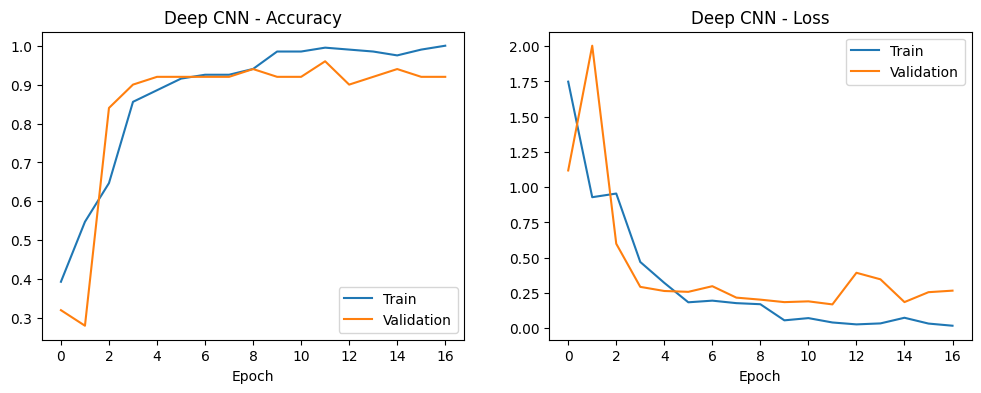

Train accuracy   : 0.99
Test accuracy    : 0.924
F1 (weighted)    : 0.924
ROC-AUC (overall): 0.986
   ROC-AUC Covid : 1.0
   ROC-AUC Normal : 0.98
   ROC-AUC Viral Pneumonia : 0.978
Trainable params : 22277955

Classification report:
                 precision    recall  f1-score   support

          Covid       1.00      1.00      1.00        26
         Normal       0.83      0.95      0.88        20
Viral Pneumonia       0.94      0.80      0.86        20

       accuracy                           0.92        66
      macro avg       0.92      0.92      0.92        66
   weighted avg       0.93      0.92      0.92        66



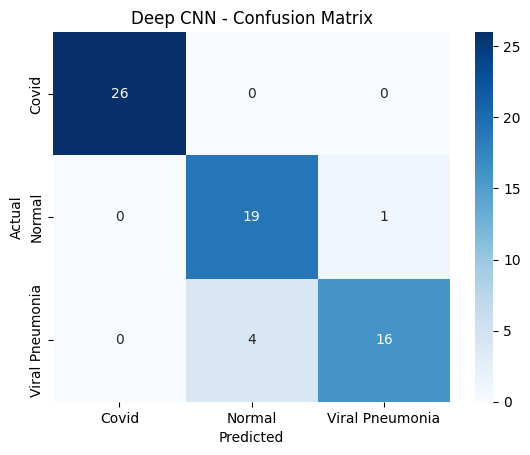

In [17]:
evaluate(cnn2, history2, 'Deep CNN')

Accuracy has increased after using Dropout and Early Stopping

### Transfer Learning Models

In [18]:
def build_transfer_model(base):
    # freeze everything, then unfreeze only the last 4 layers
    for layer in base.layers:
        layer.trainable = False
    for layer in base.layers[-4:]:
        layer.trainable = True

    x = GlobalAveragePooling2D()(base.output)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.3)(x)
    output = Dense(3, activation='softmax')(x)

    model = Model(inputs=base.input, outputs=output)
    model.compile(optimizer=Adam(1e-4), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

### Model 3: VGG16

In [19]:
vgg = VGG16(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
vgg_model = build_transfer_model(vgg)

history_vgg = vgg_model.fit(train_data, validation_data=val_data,
                            epochs=15, class_weight=class_weights, callbacks=[early_stop])

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 39s 4s/step - accuracy: 0.5224 - loss: 0.9969 - val_accuracy: 0.6400 - val_loss: 0.8627
Epoch 2/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 954ms/step - accuracy: 0.7313 - loss: 0.6505 - val_accuracy: 0.8600 - val_loss: 0.5267
Epoch 3/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 853ms/step - accuracy: 0.8657 - loss: 0.4410 - val_accuracy: 0.8600 - val_loss: 0.4155
Epoch 4/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 887ms/step - accuracy: 0.8856 - loss: 0.3331 - val_accuracy: 0.7600 - val_loss: 0.4899
Epoch 5/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 790ms/step - accuracy: 0.9254 - loss: 0.2068 - val_accuracy: 0.8200 - val_loss: 0.5267


In [20]:
loss3, acc3 = vgg_model.evaluate(test_data)

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.6970 - loss: 0.7461


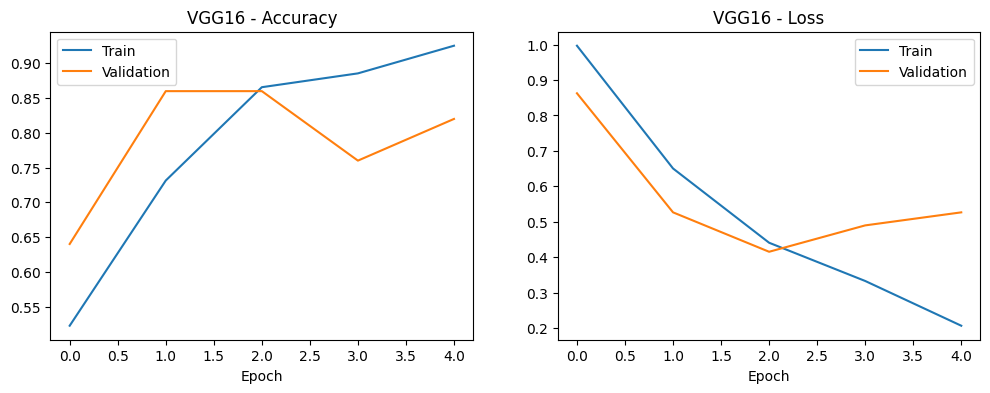

Train accuracy   : 0.801
Test accuracy    : 0.697
F1 (weighted)    : 0.681
ROC-AUC (overall): 0.956
   ROC-AUC Covid : 1.0
   ROC-AUC Normal : 0.95
   ROC-AUC Viral Pneumonia : 0.918
Trainable params : 7145475

Classification report:
                 precision    recall  f1-score   support

          Covid       1.00      0.77      0.87        26
         Normal       0.53      1.00      0.69        20
Viral Pneumonia       0.75      0.30      0.43        20

       accuracy                           0.70        66
      macro avg       0.76      0.69      0.66        66
   weighted avg       0.78      0.70      0.68        66



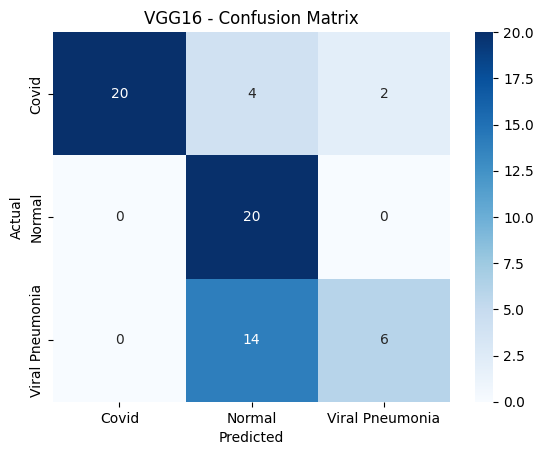

In [21]:
evaluate(vgg_model, history_vgg, 'VGG16')

VGG16 has increase the testing accuracy further but still there seems to be an overfitting issue

### Model 4: RESNET50

In [22]:
resnet = ResNet50(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
resnet_model = build_transfer_model(resnet)

history_resnet = resnet_model.fit(train_data, validation_data=val_data,
                                  epochs=15, class_weight=class_weights, callbacks=[early_stop])

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 35s 3s/step - accuracy: 0.4179 - loss: 1.1072 - val_accuracy: 0.2800 - val_loss: 1.2486
Epoch 2/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.6667 - loss: 0.9046 - val_accuracy: 0.2800 - val_loss: 1.2498
Epoch 3/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 760ms/step - accuracy: 0.6816 - loss: 0.7918 - val_accuracy: 0.2800 - val_loss: 1.2375
Epoch 4/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 855ms/step - accuracy: 0.7612 - loss: 0.6990 - val_accuracy: 0.2800 - val_loss: 1.1852
Epoch 5/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 844ms/step - accuracy: 0.7512 - loss: 0.6368 - val_accuracy: 0.4000 - val_loss: 1.1776


In [23]:
loss4, acc4 = resnet_model.evaluate(test_data)

3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.3030 - loss: 1.2104


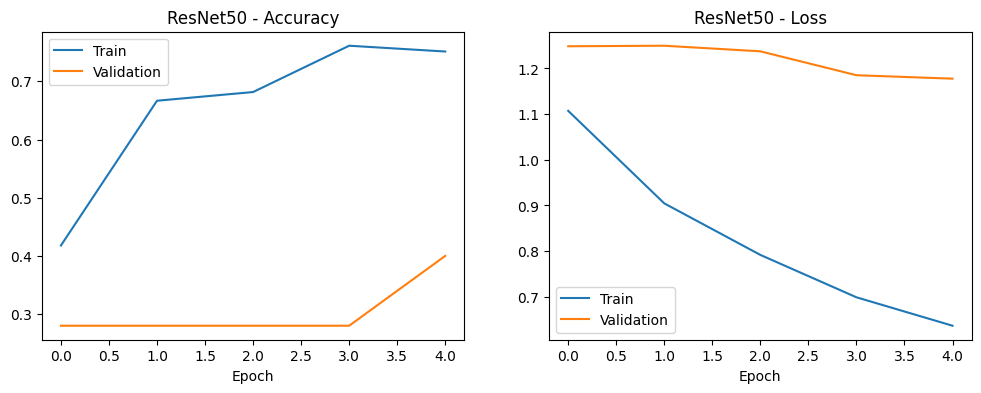

Train accuracy   : 0.279
Test accuracy    : 0.303
F1 (weighted)    : 0.141
ROC-AUC (overall): 0.695
   ROC-AUC Covid : 0.679
   ROC-AUC Normal : 0.496
   ROC-AUC Viral Pneumonia : 0.91
Trainable params : 1317379

Classification report:
                 precision    recall  f1-score   support

          Covid       0.00      0.00      0.00        26
         Normal       0.30      1.00      0.47        20
Viral Pneumonia       0.00      0.00      0.00        20

       accuracy                           0.30        66
      macro avg       0.10      0.33      0.16        66
   weighted avg       0.09      0.30      0.14        66



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


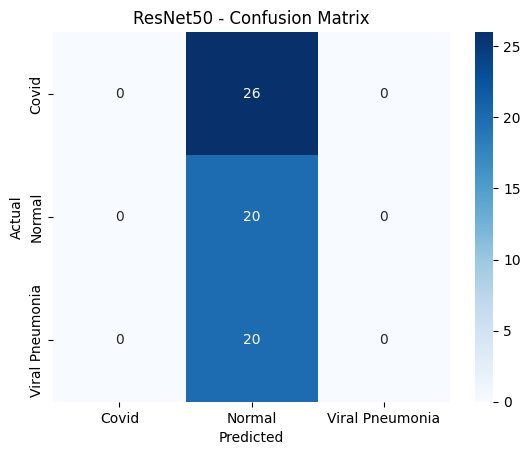

In [24]:
evaluate(resnet_model, history_resnet, 'ResNet50')

#### Model 5: Data Augmentation + VGG16

In [25]:
train_aug_gen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1,
    validation_split=0.2
)

In [26]:
train_aug = train_aug_gen.flow_from_directory(
    train_path, target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH,
    class_mode='categorical', subset='training', shuffle=True)

Found 201 images belonging to 3 classes.


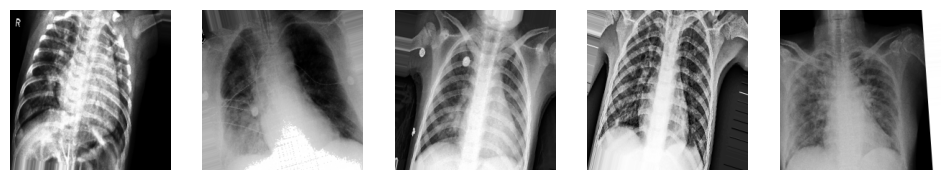

In [27]:
images, labels = next(train_aug)
plt.figure(figsize=(12, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(images[i])
    plt.axis('off')
plt.show()

In [28]:
vgg_aug = VGG16(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
vgg_aug_model = build_transfer_model(vgg_aug)

history_aug = vgg_aug_model.fit(train_aug, validation_data=val_data,
                                epochs=20, class_weight=class_weights, callbacks=[early_stop])

Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.6119 - loss: 0.8539 - val_accuracy: 0.6000 - val_loss: 0.7172
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.7562 - loss: 0.6176 - val_accuracy: 0.6800 - val_loss: 0.8030
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.8458 - loss: 0.4352 - val_accuracy: 0.8200 - val_loss: 0.5215
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.8657 - loss: 0.3681 - val_accuracy: 0.6800 - val_loss: 0.7051
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.8806 - loss: 0.3137 - val_accuracy: 0.8200 - val_loss: 0.4821


In [29]:
loss5, acc5 = vgg_aug_model.evaluate(test_data)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 435ms/step - accuracy: 0.7273 - loss: 0.5515


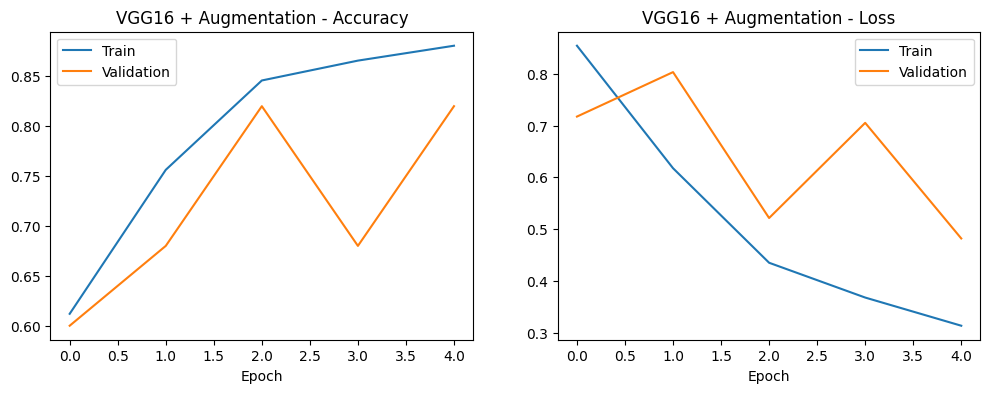

Train accuracy   : 0.706
Test accuracy    : 0.727
F1 (weighted)    : 0.654
ROC-AUC (overall): 0.984
   ROC-AUC Covid : 1.0
   ROC-AUC Normal : 0.977
   ROC-AUC Viral Pneumonia : 0.976
Trainable params : 7145475

Classification report:
                 precision    recall  f1-score   support

          Covid       0.96      1.00      0.98        26
         Normal       0.54      1.00      0.70        20
Viral Pneumonia       1.00      0.10      0.18        20

       accuracy                           0.73        66
      macro avg       0.83      0.70      0.62        66
   weighted avg       0.85      0.73      0.65        66



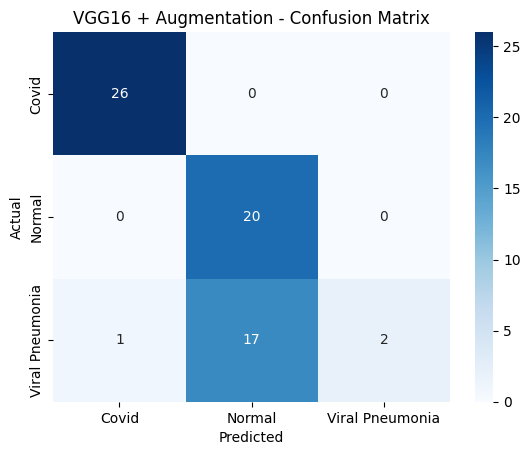

In [30]:
evaluate(vgg_aug_model, history_aug, 'VGG16 + Augmentation')

### Keras Tuner

In [31]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 9.5 MB/s eta 0:00:00


In [32]:
from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

import keras_tuner as kt

In [33]:
def build_model(hp):
    model = Sequential([
        Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        Conv2D(hp.Int('filters1', 32, 128, step=32), (3, 3), activation='relu'),
        MaxPooling2D(),
        Conv2D(hp.Int('filters2', 32, 128, step=32), (3, 3), activation='relu'),
        MaxPooling2D(),
        Flatten(),
        Dense(hp.Int('dense', 64, 256, step=64), activation='relu'),
        Dropout(hp.Choice('dropout', [0.2, 0.3, 0.5])),
        Dense(3, activation='softmax')
    ])

    lr = hp.Choice('lr', [1e-3, 1e-4])
    if hp.Choice('optimizer', ['adam', 'rmsprop']) == 'adam':
        opt = tf.keras.optimizers.Adam(lr)
    else:
        opt = tf.keras.optimizers.RMSprop(lr)

    model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
    return model



In [34]:
tuner = kt.RandomSearch(build_model, objective='val_accuracy', max_trials=5,
                        directory='kt_dir', project_name='covid', overwrite=True)

In [35]:
tuner.search(train_data, validation_data=val_data, epochs=10,
             class_weight=class_weights, callbacks=[early_stop])

Trial 5 Complete [00h 00m 47s]
val_accuracy: 0.9200000166893005

Best val_accuracy So Far: 0.9200000166893005
Total elapsed time: 00h 04m 49s


In [36]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print(best_hp.values)

{'filters1': 96, 'filters2': 64, 'dense': 128, 'dropout': 0.3, 'lr': 0.001, 'optimizer': 'rmsprop'}


In [37]:
tuned_cnn = tuner.hypermodel.build(best_hp)
history_tuned = tuned_cnn.fit(train_data, validation_data=val_data,
                              epochs=20, class_weight=class_weights, callbacks=[early_stop])
tuned_cnn.summary()

Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.3881 - loss: 7.0963 - val_accuracy: 0.4800 - val_loss: 1.0437
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 801ms/step - accuracy: 0.5821 - loss: 1.0429 - val_accuracy: 0.6200 - val_loss: 0.8004
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 708ms/step - accuracy: 0.5970 - loss: 0.9923 - val_accuracy: 0.5600 - val_loss: 0.7904
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 817ms/step - accuracy: 0.7413 - loss: 0.6088 - val_accuracy: 0.6600 - val_loss: 0.7305
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 709ms/step - accuracy: 0.7960 - loss: 0.7691 - val_accuracy: 0.8000 - val_loss: 0.4948


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 222, 222, 96)   │         2,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 111, 111, 96)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 109, 109, 64)   │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    23,888,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,892,872 (182.70 MB)

 Trainable params: 23,946,435 (91.35 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 23,946,437 (91.35 MB)

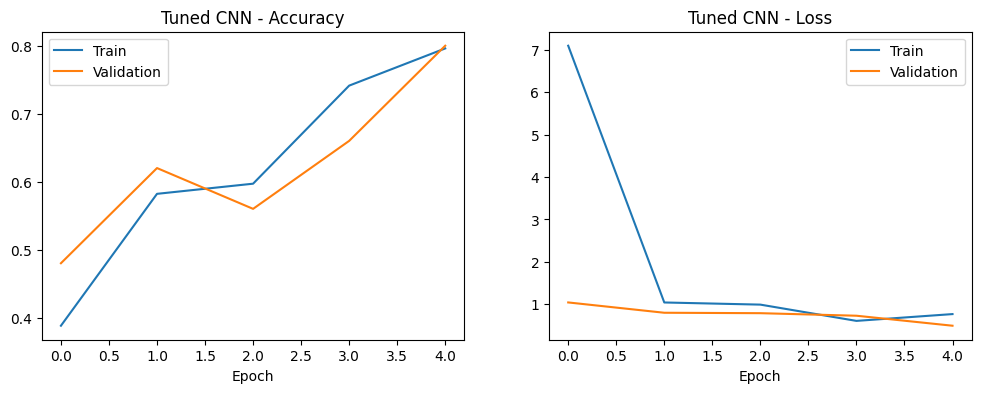

Train accuracy   : 0.512
Test accuracy    : 0.409
F1 (weighted)    : 0.254
ROC-AUC (overall): 0.629
   ROC-AUC Covid : 0.468
   ROC-AUC Normal : 0.843
   ROC-AUC Viral Pneumonia : 0.574
Trainable params : 23946435

Classification report:
                 precision    recall  f1-score   support

          Covid       0.40      1.00      0.57        26
         Normal       1.00      0.05      0.10        20
Viral Pneumonia       0.00      0.00      0.00        20

       accuracy                           0.41        66
      macro avg       0.47      0.35      0.22        66
   weighted avg       0.46      0.41      0.25        66



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


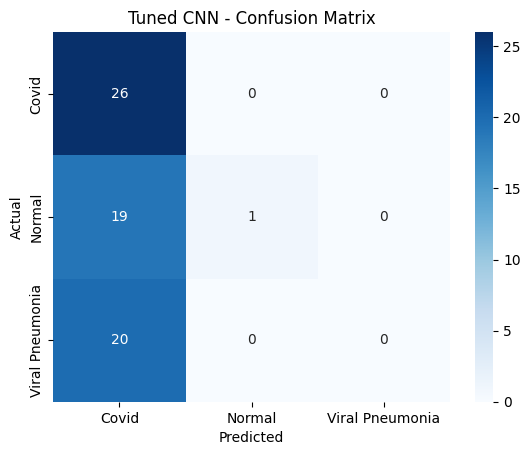

In [38]:
evaluate(tuned_cnn, history_tuned, 'Tuned CNN')

### Model Comparison Table

In [39]:
table = pd.DataFrame(results)

# Show accuracy as a percentage
table['Train Acc'] = (table['Train Acc'] * 100).round(1)
table['Test Acc'] = (table['Test Acc'] * 100).round(1)
table = table.rename(columns={'Train Acc': 'Train Acc (%)', 'Test Acc': 'Test Acc (%)'})

# Best model = NOT overfitted + highest test accuracy (F1 breaks ties)
not_overfit = table[table['Overfitting (Y/N)'] == 'N']
if len(not_overfit) == 0:          # if every model overfits, pick from all
    not_overfit = table
best_name = not_overfit.sort_values(['Test Acc (%)', 'F1 Score'], ascending=False).iloc[0]['Model']

best_row = table[table['Model'] == best_name].iloc[0].copy()
best_row['Model'] = 'Best Model -> ' + best_name
table = pd.concat([table, best_row.to_frame().T], ignore_index=True)

print('Best model (not overfitted, highest test accuracy):', best_name)
table

Best model (not overfitted, highest test accuracy): Deep CNN


,Model,Train Acc (%),Test Acc (%),F1 Score,ROC AUC,Trainable Params,Overfitting (Y/N)
0,CNN Basic,100.0,89.4,0.889,0.977,50468227,Y
1,Deep CNN,99.0,92.4,0.924,0.986,22277955,N
2,VGG16,80.1,69.7,0.681,0.956,7145475,Y
3,ResNet50,27.9,30.3,0.141,0.695,1317379,N
4,VGG16 + Augmentation,70.6,72.7,0.654,0.984,7145475,N
5,Tuned CNN,51.2,40.9,0.254,0.629,23946435,Y
6,Best Model -> Deep CNN,99.0,92.4,0.924,0.986,22277955,N


### Saving Best Model

In [40]:
all_models[best_name].save('best_model.keras')
print('Saved:', best_name)

Saved: Deep CNN


In [41]:
from google.colab import files
files.download('best_model.keras')
print('Class order:', class_names)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Class order: ['Covid', 'Normal', 'Viral Pneumonia']
